# 152Sm(n,g)153Sm: capture cross section of a medical-isotope target, predicted from the other isotopes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xsml import data, features, splits, models, metrics, importance

In [2]:
# load the table and take neutron capture, unqualified cross sections
table = data.load()
capture = data.select(table, projectile="n", mt=102, plain=True)
capture = features.append(capture)
capture = capture.reset_index(drop=True)
capture["iso"] = data.isotope_id(capture.Z, capture.A)
print(len(capture), "points,", capture.iso.nunique(), "isotopes")
print(capture.reaction.value_counts().head(3))

234733 points, 296 isotopes
reaction
93-NP-237(N,G)93-NP-238,,SIG    55961
95-AM-243(N,G)95-AM-244,,SIG    16817
95-AM-241(N,G)95-AM-242,,SIG    16622
Name: count, dtype: int64


In [3]:
# the target isotope is held out: none of its rows is used for training
Z_target = 62
A_target = 152
train_mask, test_mask = splits.leave_one_isotope_out(capture, Z_target, A_target)
train = capture[train_mask].reset_index(drop=True)
target = capture[test_mask].reset_index(drop=True)
splits.assert_no_leakage(train, target)
print(len(train), "training points,", len(target), "points of the target")
print(data.datasets(target)[["dataset", "author", "year", "points", "e_min_eV", "e_max_eV"]])

234653 training points, 80 points of the target
     dataset          author  year  points      e_min_eV      e_max_eV
0   11399040         Macklin  1957       1  2.400000e+04  2.400000e+04
1   11407028            Lyon  1959       1  1.950000e+05  1.950000e+05
2   12095007         Macklin  1963       1  3.000000e+04  3.000000e+04
3   20638048      Tattersall  1960       1  2.530000e-02  2.530000e-02
4   21325012       Pattenden  1958       1  2.530000e-02  2.530000e-02
5   22612005          Bensch  1971       4  2.400000e+04  9.740000e+05
6   22964002         Karadag  2007       1  2.500000e-02  2.500000e-02
7   23266135  Farina arbocco  2013       3  2.530000e-02  2.530000e-02
8   23488067        De corte  1988       1  2.530000e-02  2.530000e-02
9   30031021            Peto  1967       1  3.000000e+06  3.000000e+06
10  30079031         Chaubey  1966       1  2.400000e+04  2.400000e+04
11  30502014        Siddappa  1900       1  2.300000e+04  2.300000e+04
12  30685003    Zhou Zu-ying 

In [4]:
# all features: the energy and every nuclear property from the mass table
all_features = [
    "log10_energy", "Z", "N", "A", "atomic_mass_u", "mass_excess", "binding_energy", "B_per_A",
    "S_n", "S_p", "S_2n", "S_2p", "Q_alpha", "Q_beta_minus", "Q_reaction", "Q_np", "Q_na", "Q_n2n",
    "N_minus_Z", "asymmetry", "Z_odd", "N_odd", "A_odd", "pairing",
    "Z_magic_dist", "N_magic_dist", "Z_magic", "N_magic", "P_factor", "A_third", "radius_fm",
]

model_all = models.xgboost()
model_all.fit(train[all_features], train.log10_sigma)
prediction = model_all.predict(target[all_features])
factor_all = metrics.rms_factor(target.log10_sigma, prediction)
print("all features, all energies: RMS factor on the target", round(factor_all, 2))

all features, all energies: RMS factor on the target 3.17


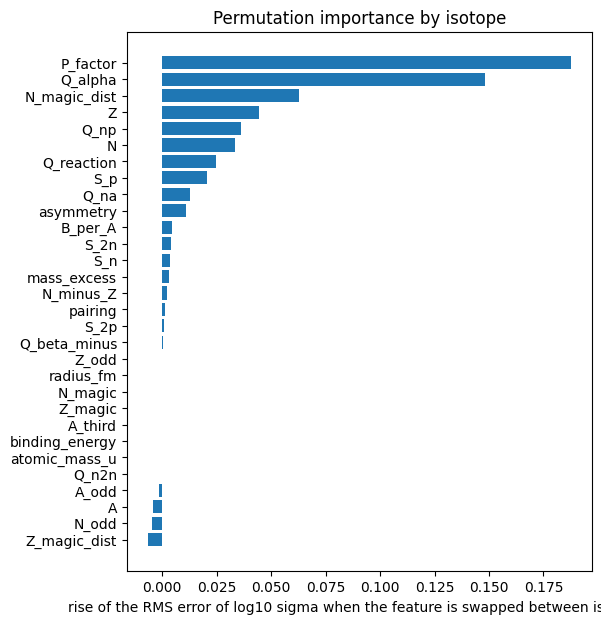

In [5]:
# naive feature importance: swap one feature between isotopes and see how much the error grows
# (measured on isotopes that the model did not train on; the energy is not an isotope property and is left out)
fold = splits.isotope_folds(train, 5)
fit_part = train[fold != 0]
check_part = train[fold == 0]
model_check = models.xgboost()
model_check.fit(fit_part[all_features], fit_part.log10_sigma)

names = []
rises = []
for name in all_features:
    if name == "log10_energy":
        continue
    result = importance.block_permutation(model_check, check_part[all_features], check_part.log10_sigma, check_part.iso, name, n_repeats=5)
    names.append(name)
    rises.append(result["mean"])
ranking = pd.Series(rises, index=names).sort_values()

plt.figure(figsize=(6, 7))
plt.barh(ranking.index, ranking.values)
plt.xlabel("rise of the RMS error of log10 sigma when the feature is swapped between isotopes")
plt.title("Permutation importance by isotope")
plt.show()

In [6]:
# trim the training set: keep 1 keV to 20 MeV (above the resolved resonances) and drop the other samarium isotopes
train_trim = train[(train.energy_eV >= 1e3) & (train.energy_eV <= 2e7)]
train_trim = train_trim[train_trim.Z != Z_target]
train_trim = train_trim.reset_index(drop=True)
target_trim = target[(target.energy_eV >= 1e3) & (target.energy_eV <= 2e7)].reset_index(drop=True)
splits.assert_no_leakage(train_trim, target_trim, level="element")
print(len(train_trim), "training points after trimming,", train_trim.iso.nunique(), "isotopes,", len(target_trim), "target points")

63716 training points after trimming, 217 isotopes, 68 target points


In [7]:
# three algorithms, cross-validated over isotopes on the trimmed training set
cv = splits.fold_splits(train_trim, 5)
algorithms = {
    "decision tree": models.decision_tree(),
    "random forest": models.random_forest(n_estimators=100),
    "XGBoost": models.xgboost(),
}
cv_scores = {}
target_scores = {}
fitted = {}
for name in algorithms:
    model = algorithms[name]
    rmse, out_of_fold = models.cv_rmse(model, train_trim[all_features], train_trim.log10_sigma, cv)
    cv_scores[name] = metrics.cluster_bootstrap(train_trim.log10_sigma, out_of_fold, train_trim.iso, n_boot=500)
    model.fit(train_trim[all_features], train_trim.log10_sigma)
    fitted[name] = model
    target_scores[name] = metrics.rms_factor(target_trim.log10_sigma, model.predict(target_trim[all_features]))
    print(name, "CV RMS factor", round(cv_scores[name]["value"], 2), "[", round(cv_scores[name]["low"], 2), ",", round(cv_scores[name]["high"], 2), "]",
          " target", round(target_scores[name], 2))

decision tree CV RMS factor 3.54 [ 2.97 , 4.48 ]  target 2.62
random forest CV RMS factor 2.88 [ 2.25 , 3.98 ]  target 2.3
XGBoost CV RMS factor 2.73 [ 2.21 , 3.58 ]  target 2.36


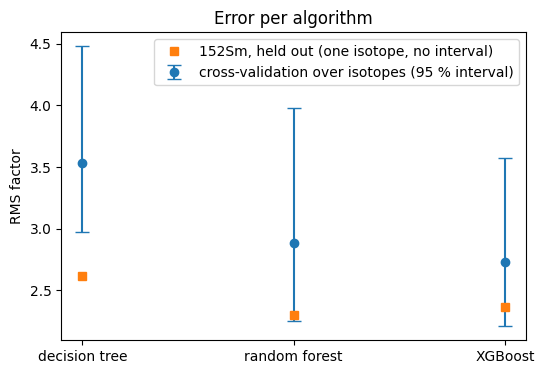

In [8]:
# error per algorithm, with the interval over isotopes
labels = list(cv_scores.keys())
values = np.array([cv_scores[name]["value"] for name in labels])
lows = np.array([cv_scores[name]["low"] for name in labels])
highs = np.array([cv_scores[name]["high"] for name in labels])
on_target = np.array([target_scores[name] for name in labels])

plt.figure(figsize=(6, 4))
plt.errorbar(labels, values, yerr=[values - lows, highs - values], fmt="o", capsize=5, label="cross-validation over isotopes (95 % interval)")
plt.plot(labels, on_target, "s", label="152Sm, held out (one isotope, no interval)")
plt.ylabel("RMS factor")
plt.title("Error per algorithm")
plt.legend()
plt.show()

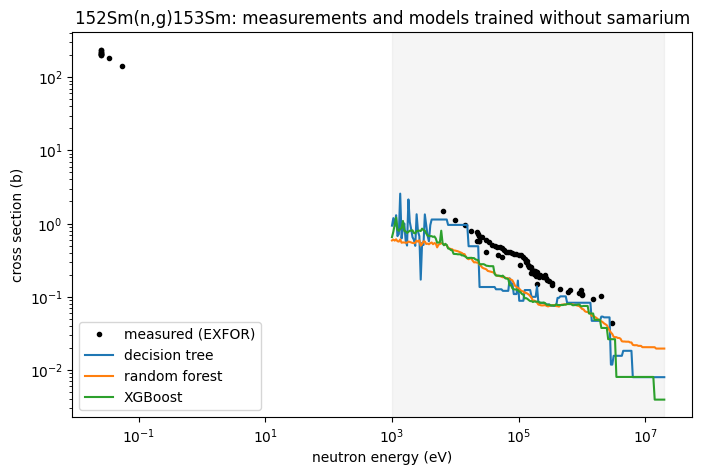

In [9]:
# the data of 152Sm and the three model curves
grid = pd.DataFrame({"projectile": "n", "Z": Z_target, "A": A_target, "MT": 102, "reaction": target.reaction.iloc[0],
                     "energy_eV": np.logspace(3, np.log10(2e7), 200), "sigma_b": 1.0})
grid = features.append(grid)

plt.figure(figsize=(8, 5))
plt.loglog(target.energy_eV, target.sigma_b, "k.", label="measured (EXFOR)")
for name in fitted:
    plt.loglog(grid.energy_eV, 10 ** fitted[name].predict(grid[all_features]), label=name)
plt.axvspan(1e3, 2e7, alpha=0.08, color="grey")
plt.xlabel("neutron energy (eV)")
plt.ylabel("cross section (b)")
plt.title("152Sm(n,g)153Sm: measurements and models trained without samarium")
plt.legend()
plt.show()

In [10]:
# log every score
log = "score_log_examples.csv"
metrics.log_score(log, model="XGBoost", features=all_features, split="152Sm held out, all energies", metric="rms_factor",
                  value=factor_all, n_groups=1, n_points=len(target), notes="no interval: one isotope")
for name in labels:
    metrics.log_score(log, model=name, features=all_features, split="5 isotope folds, 1 keV to 20 MeV, no Sm", metric="rms_factor",
                      value=cv_scores[name]["value"], ci_low=cv_scores[name]["low"], ci_high=cv_scores[name]["high"],
                      n_groups=cv_scores[name]["n_groups"], n_points=cv_scores[name]["n_points"])
    metrics.log_score(log, model=name, features=all_features, split="152Sm held out, 1 keV to 20 MeV, no Sm in training", metric="rms_factor",
                      value=target_scores[name], n_groups=1, n_points=len(target_trim), notes="no interval: one isotope")
print(pd.read_csv(log).tail(7)[["model", "split", "value", "ci_low", "ci_high"]].to_string())

           model                                               split     value    ci_low   ci_high
0        XGBoost                        152Sm held out, all energies  3.174522       NaN       NaN
1  decision tree             5 isotope folds, 1 keV to 20 MeV, no Sm  3.535523  2.971570  4.479781
2  decision tree  152Sm held out, 1 keV to 20 MeV, no Sm in training  2.616707       NaN       NaN
3  random forest             5 isotope folds, 1 keV to 20 MeV, no Sm  2.882182  2.250041  3.981376
4  random forest  152Sm held out, 1 keV to 20 MeV, no Sm in training  2.301182       NaN       NaN
5        XGBoost             5 isotope folds, 1 keV to 20 MeV, no Sm  2.732472  2.206896  3.576172
6        XGBoost  152Sm held out, 1 keV to 20 MeV, no Sm in training  2.364726       NaN       NaN
